In [7]:
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("log_perso_2024-08-23.csv", names=['url', '#commits', '#files', 'time'])
df_signi = df[df['#commits']>0]
df_signi

,url,#commits,#files,time
5,https://github.com/0xInfection/Awesome-WAF,229,33,0.754809
6,https://github.com/codertimo/BERT-pytorch,142,99,0.958049
7,https://github.com/MingchaoZhu/DeepLearning,27,57,0.708605
8,https://github.com/ShangtongZhang/reinforcemen...,398,163,0.707199
9,https://github.com/chineseocr/chineseocr,133,599,0.790623
...,...,...,...,...
421,https://github.com/PaddlePaddle/PaddleDetection,53185,20802,162.716721
422,https://github.com/MycroftAI/mycroft-core,535575,2875,176.224678
423,https://github.com/NVIDIA/NeMo,90420,18325,222.094892
424,https://github.com/PaddlePaddle/PaddleNLP,40951,23872,229.064295


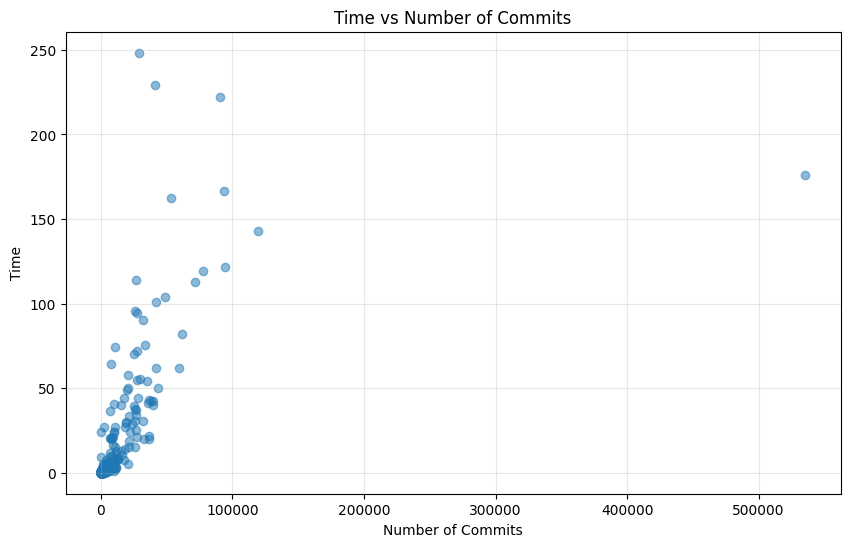

In [9]:
plt.figure(figsize=(10, 6))
plt.scatter(df_signi['#commits'], df_signi['time'], alpha=0.5)
plt.xlabel('Number of Commits')
plt.ylabel('Time')
plt.title('Time vs Number of Commits')
plt.grid(True, alpha=0.3)
plt.show()

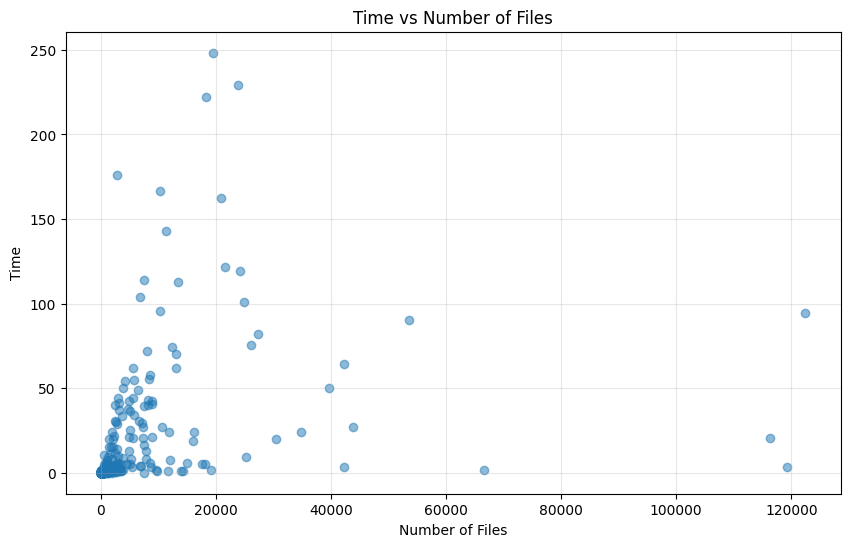

In [10]:
plt.figure(figsize=(10, 6))
plt.scatter(df_signi['#files'], df_signi['time'], alpha=0.5)
plt.xlabel('Number of Files')
plt.ylabel('Time')
plt.title('Time vs Number of Files')
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
import warnings
warnings.filterwarnings('ignore')

# Remove any rows with missing values
df_clean = df_signi.dropna()

# Prepare data for commits
X_commits = df_clean['#commits'].values.reshape(-1, 1)
X_files = df_clean['#files'].values.reshape(-1, 1)
y = df_clean['time'].values

# Filter out zeros for log transformations
mask_commits = (df_clean['#commits'] > 0) & (df_clean['time'] > 0)
mask_files = (df_clean['#files'] > 0) & (df_clean['time'] > 0)

def fit_models(X, y, mask, name):
    """Fit different regression models and return R² scores"""
    results = {}
    
    # Linear
    lr = LinearRegression()
    lr.fit(X, y)
    y_pred = lr.predict(X)
    results['Linear'] = r2_score(y, y_pred)
    
    # Polynomial (degree 2)
    poly2 = PolynomialFeatures(degree=2)
    X_poly2 = poly2.fit_transform(X)
    lr2 = LinearRegression()
    lr2.fit(X_poly2, y)
    y_pred2 = lr2.predict(X_poly2)
    results['Polynomial (deg 2)'] = r2_score(y, y_pred2)
    
    # Polynomial (degree 3)
    poly3 = PolynomialFeatures(degree=3)
    X_poly3 = poly3.fit_transform(X)
    lr3 = LinearRegression()
    lr3.fit(X_poly3, y)
    y_pred3 = lr3.predict(X_poly3)
    results['Polynomial (deg 3)'] = r2_score(y, y_pred3)
    
    # Logarithmic (log(x) vs y)
    X_log = np.log(X[mask] + 1).reshape(-1, 1)
    y_log = y[mask]
    lr_log = LinearRegression()
    lr_log.fit(X_log, y_log)
    y_pred_log = lr_log.predict(X_log)
    results['Logarithmic'] = r2_score(y_log, y_pred_log)
    
    # Power law (log(x) vs log(y))
    X_log_power = np.log(X[mask] + 1).reshape(-1, 1)
    y_log_power = np.log(y[mask] + 1)
    lr_power = LinearRegression()
    lr_power.fit(X_log_power, y_log_power)
    y_pred_power = lr_power.predict(X_log_power)
    results['Power Law'] = r2_score(y_log_power, y_pred_power)
    
    print(f"\n{name} - R² scores:")
    print("-" * 40)
    for model, score in sorted(results.items(), key=lambda x: x[1], reverse=True):
        print(f"{model:20s}: {score:.4f}")
    
    return results

# Fit models for both relationships
commits_results = fit_models(X_commits, y, mask_commits, "TIME vs #COMMITS")
files_results = fit_models(X_files, y, mask_files, "TIME vs #FILES")


TIME vs #COMMITS - R² scores:
----------------------------------------
Polynomial (deg 3)  : 0.6991
Polynomial (deg 2)  : 0.6986
Power Law           : 0.6975
Linear              : 0.3737
Logarithmic         : 0.3469

TIME vs #FILES - R² scores:
----------------------------------------
Power Law           : 0.5900
Polynomial (deg 3)  : 0.4191
Polynomial (deg 2)  : 0.3131
Logarithmic         : 0.2669
Linear              : 0.1248


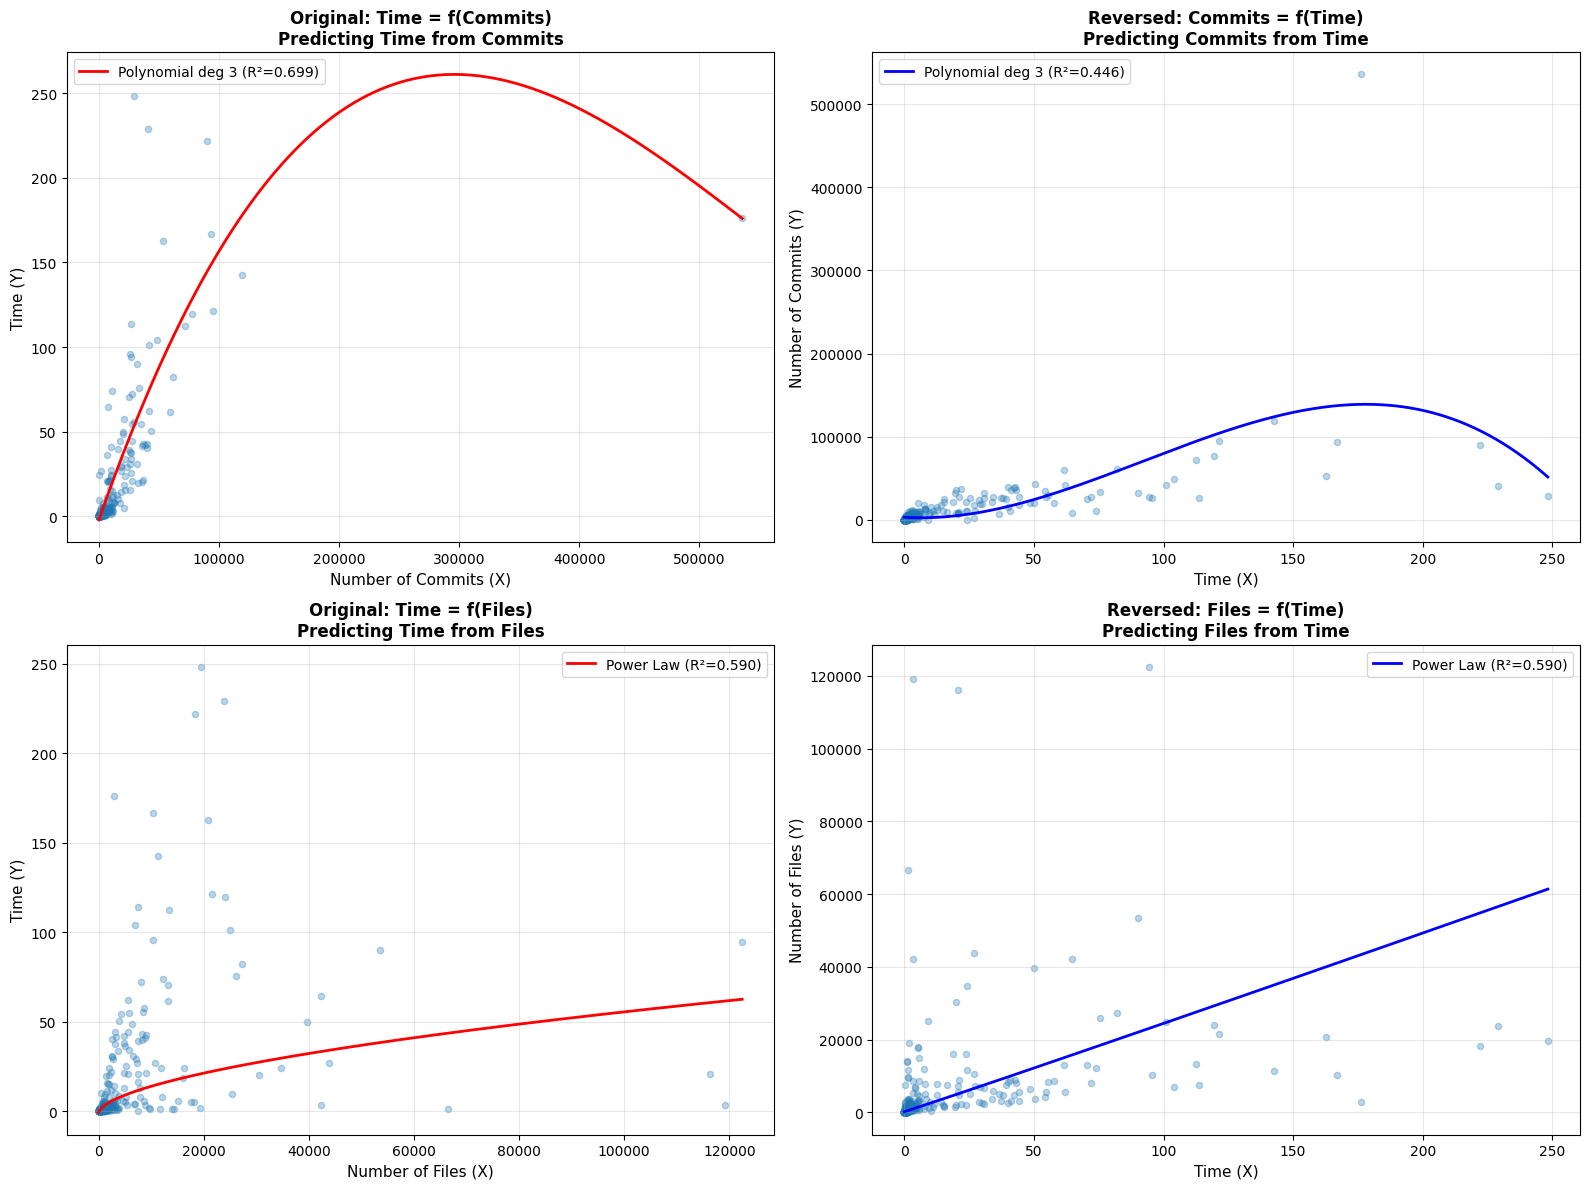


Comparison of Regression Directions:

COMMITS (Polynomial deg 3):
  Time = f(Commits):   R² = 0.6991
  Commits = f(Time):   R² = 0.4460

FILES (Power Law):
  Time = f(Files):     R² = 0.5900
  Files = f(Time):     R² = 0.5900

REGRESSION EQUATIONS:

Original Direction (predicting Time):
  Time vs #Commits (Polynomial deg 3):
    Time ≈ -2.270696796753759 + 0.00203006921834941xC + -4.6939297720488355e-09xC² + 2.84779707605478e-15xC³
    where C = #Commits
  Time vs #Files (Power Law):
    Time ≈ 0.07112065237624607 x (#Files)^0.5799202764569397

Reversed Direction (predicting Size):
  #Commits vs Time (Polynomial deg 3):
    #Commits ≈ 3280.6034 + -188.4040xT + 14.963142xT² + -0.054046952xT³
    where T = Time
  #Files vs Time (Power Law):
    #Files ≈ 223.60 x (Time)^1.017


In [12]:
# Compare both regression directions
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# === TIME vs #COMMITS ===
# Original: predicting Time from Commits using Polynomial (deg 3)
ax1 = axes[0, 0]
ax1.scatter(df_clean['#commits'], df_clean['time'], alpha=0.3, s=20)
poly3_c = PolynomialFeatures(degree=3)
X_poly3_c = poly3_c.fit_transform(X_commits)
lr_c = LinearRegression()
lr_c.fit(X_poly3_c, y)
r2_commits = r2_score(y, lr_c.predict(X_poly3_c))
X_range_c = np.linspace(X_commits.min(), X_commits.max(), 1000).reshape(-1, 1)
X_range_poly3_c = poly3_c.transform(X_range_c)
y_pred_c = lr_c.predict(X_range_poly3_c)
ax1.plot(X_range_c, y_pred_c, 'r-', linewidth=2, label=f'Polynomial deg 3 (R²={r2_commits:.3f})')
ax1.set_xlabel('Number of Commits (X)', fontsize=11)
ax1.set_ylabel('Time (Y)', fontsize=11)
ax1.set_title('Original: Time = f(Commits)\nPredicting Time from Commits', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Reversed: predicting Commits from Time using Polynomial (deg 3)
ax2 = axes[0, 1]
ax2.scatter(df_clean['time'], df_clean['#commits'], alpha=0.3, s=20)
y_reshaped = y.reshape(-1, 1)
poly3_c_rev = PolynomialFeatures(degree=3)
y_poly3_rev = poly3_c_rev.fit_transform(y_reshaped)
lr_c_rev = LinearRegression()
lr_c_rev.fit(y_poly3_rev, X_commits)
r2_commits_rev = r2_score(X_commits, lr_c_rev.predict(y_poly3_rev))
y_range = np.linspace(y.min(), y.max(), 1000).reshape(-1, 1)
y_range_poly3 = poly3_c_rev.transform(y_range)
x_pred_c = lr_c_rev.predict(y_range_poly3)
ax2.plot(y_range, x_pred_c, 'b-', linewidth=2, label=f'Polynomial deg 3 (R²={r2_commits_rev:.3f})')
ax2.set_xlabel('Time (X)', fontsize=11)
ax2.set_ylabel('Number of Commits (Y)', fontsize=11)
ax2.set_title('Reversed: Commits = f(Time)\nPredicting Commits from Time', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend()

# === TIME vs #FILES ===
# Original: predicting Time from Files
ax3 = axes[1, 0]
ax3.scatter(df_clean['#files'], df_clean['time'], alpha=0.3, s=20)
X_log_f = np.log(X_files[mask_files] + 1)
y_log_f = np.log(y[mask_files] + 1)
lr_f = LinearRegression()
lr_f.fit(X_log_f, y_log_f)
r2_files = r2_score(y_log_f, lr_f.predict(X_log_f))
X_range_f = np.linspace(X_files.min(), X_files.max(), 1000).reshape(-1, 1)
y_pred_f = np.exp(lr_f.predict(np.log(X_range_f + 1))) - 1
ax3.plot(X_range_f, y_pred_f, 'r-', linewidth=2, label=f'Power Law (R²={r2_files:.3f})')
ax3.set_xlabel('Number of Files (X)', fontsize=11)
ax3.set_ylabel('Time (Y)', fontsize=11)
ax3.set_title('Original: Time = f(Files)\nPredicting Time from Files', fontsize=12, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.legend()

# Reversed: predicting Files from Time
ax4 = axes[1, 1]
ax4.scatter(df_clean['time'], df_clean['#files'], alpha=0.3, s=20)
lr_f_rev = LinearRegression()
lr_f_rev.fit(y_log_f.reshape(-1, 1), X_log_f.ravel())
r2_files_rev = r2_score(X_log_f.ravel(), lr_f_rev.predict(y_log_f.reshape(-1, 1)))
mask_y = y_range > 0
x_pred_f = np.exp(lr_f_rev.predict(np.log(y_range[mask_y.ravel()] + 1))) - 1
ax4.plot(y_range[mask_y.ravel()], x_pred_f, 'b-', linewidth=2, label=f'Power Law (R²={r2_files_rev:.3f})')
ax4.set_xlabel('Time (X)', fontsize=11)
ax4.set_ylabel('Number of Files (Y)', fontsize=11)
ax4.set_title('Reversed: Files = f(Time)\nPredicting Files from Time', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3)
ax4.legend()

plt.tight_layout()
plt.show()

print("\nComparison of Regression Directions:")
print("="*60)
print("\nCOMMITS (Polynomial deg 3):")
print(f"  Time = f(Commits):   R² = {r2_commits:.4f}")
print(f"  Commits = f(Time):   R² = {r2_commits_rev:.4f}")
print("\nFILES (Power Law):")
print(f"  Time = f(Files):     R² = {r2_files:.4f}")
print(f"  Files = f(Time):     R² = {r2_files_rev:.4f}")

print("\n" + "="*60)
print("REGRESSION EQUATIONS:")
print("="*60)
print("\nOriginal Direction (predicting Time):")
# Polynomial equation for commits
coeffs_c = lr_c.coef_
intercept_c = lr_c.intercept_
print(f"  Time vs #Commits (Polynomial deg 3):")
print(f"    Time ≈ {intercept_c} + {coeffs_c[1]}xC + {coeffs_c[2]}xC² + {coeffs_c[3]}xC³")
print(f"    where C = #Commits")
print(f"  Time vs #Files (Power Law):")
print(f"    Time ≈ {np.exp(lr_f.intercept_)} x (#Files)^{lr_f.coef_[0]}")

print("\nReversed Direction (predicting Size):")
# Polynomial equation for reversed commits
coeffs_c_rev = lr_c_rev.coef_
intercept_c_rev = lr_c_rev.intercept_
print(f"  #Commits vs Time (Polynomial deg 3):")
print(f"    #Commits ≈ {intercept_c_rev[0]:.4f} + {coeffs_c_rev[0][1]:.4f}xT + {coeffs_c_rev[0][2]:.6f}xT² + {coeffs_c_rev[0][3]:.9f}xT³")
print(f"    where T = Time")
print(f"  #Files vs Time (Power Law):")
print(f"    #Files ≈ {np.exp(lr_f_rev.intercept_):.2f} x (Time)^{lr_f_rev.coef_[0]:.3f}")